# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

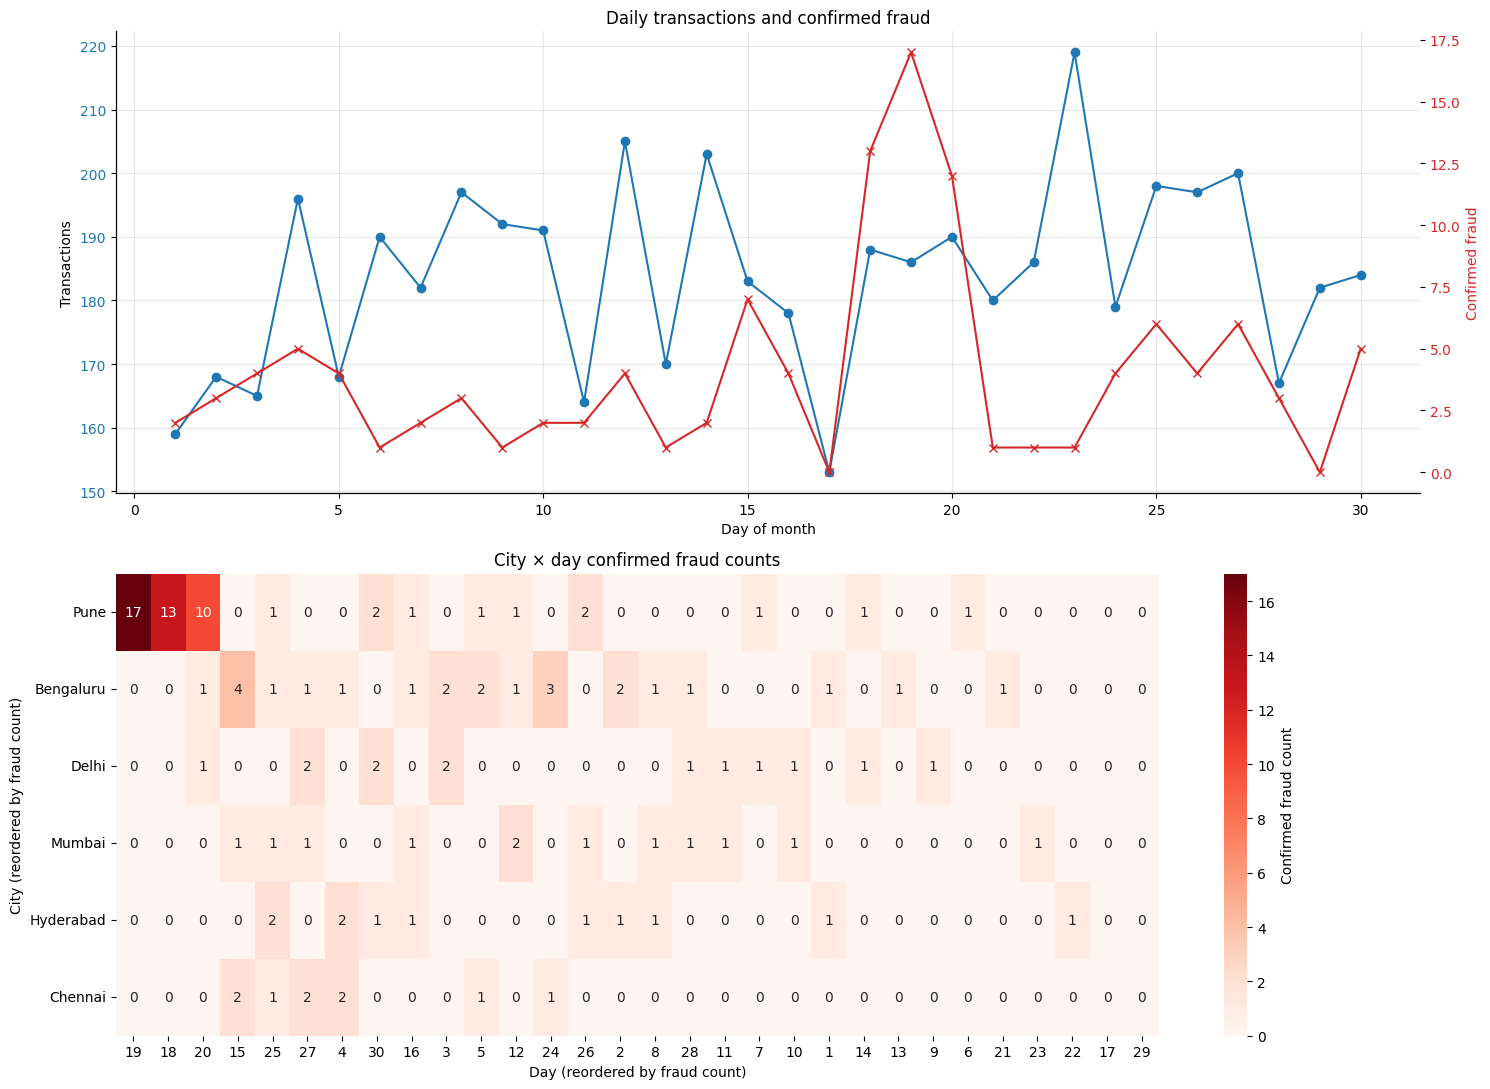

Top city/day fraud hotspots:
  Pune, day 19: 17
  Pune, day 18: 13
  Pune, day 20: 10


In [2]:
import seaborn as sns

daily_summary = tx.groupby('day').agg(total_tx=('is_fraud', 'size'), fraud_tx=('is_fraud', 'sum'))
days = sorted(tx['day'].unique())
cities = sorted(tx['city'].unique())

fig, axes = plt.subplots(2, 1, figsize=(15, 11))
ax = axes[0]
ax.plot(daily_summary.index, daily_summary.total_tx, marker='o', color='tab:blue', label='All transactions')
ax.set(xlabel='Day of month', ylabel='Transactions', title='Daily transactions and confirmed fraud')
ax.tick_params(axis='y', labelcolor='tab:blue')
ax.grid(alpha=0.3)
ax2 = ax.twinx()
ax2.plot(daily_summary.index, daily_summary.fraud_tx, marker='x', color='tab:red', label='Confirmed fraud')
ax2.set_ylabel('Confirmed fraud', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

# Include EVERY city and day from the complete transaction table, even if zero fraud.
fraud_tx = tx.loc[tx.is_fraud == 1]
heatmap_data = (fraud_tx.groupby(['city','day']).size().unstack(fill_value=0)
                .reindex(index=cities, columns=days, fill_value=0))
row_order = heatmap_data.sum(axis=1).sort_values(ascending=False).index
col_order = heatmap_data.sum(axis=0).sort_values(ascending=False).index
heatmap_reordered = heatmap_data.loc[row_order, col_order]
sns.heatmap(heatmap_reordered, annot=True, fmt='d', cmap='Reds', ax=axes[1],
            cbar_kws={'label': 'Confirmed fraud count'})
axes[1].set(xlabel='Day (reordered by fraud count)', ylabel='City (reordered by fraud count)',
            title='City × day confirmed fraud counts')
plt.tight_layout()
plt.show()

top_cells = heatmap_data.stack().sort_values(ascending=False).head(3)
print('Top city/day fraud hotspots:')
for (city, day), count in top_cells.items():
    print(f'  {city}, day {day}: {count}')


The high-level overview instantly made a major, localized spatial-temporal cluster of fraud visible in Pune during Days 18-20. An alert list sorted purely by detector score would scatter these events randomly across pages, obscuring their commonalities. I detected this pattern using a reordered matrix (matrix reordering), which grouped high-volume dimensions together to reveal the distinct visual cluster.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

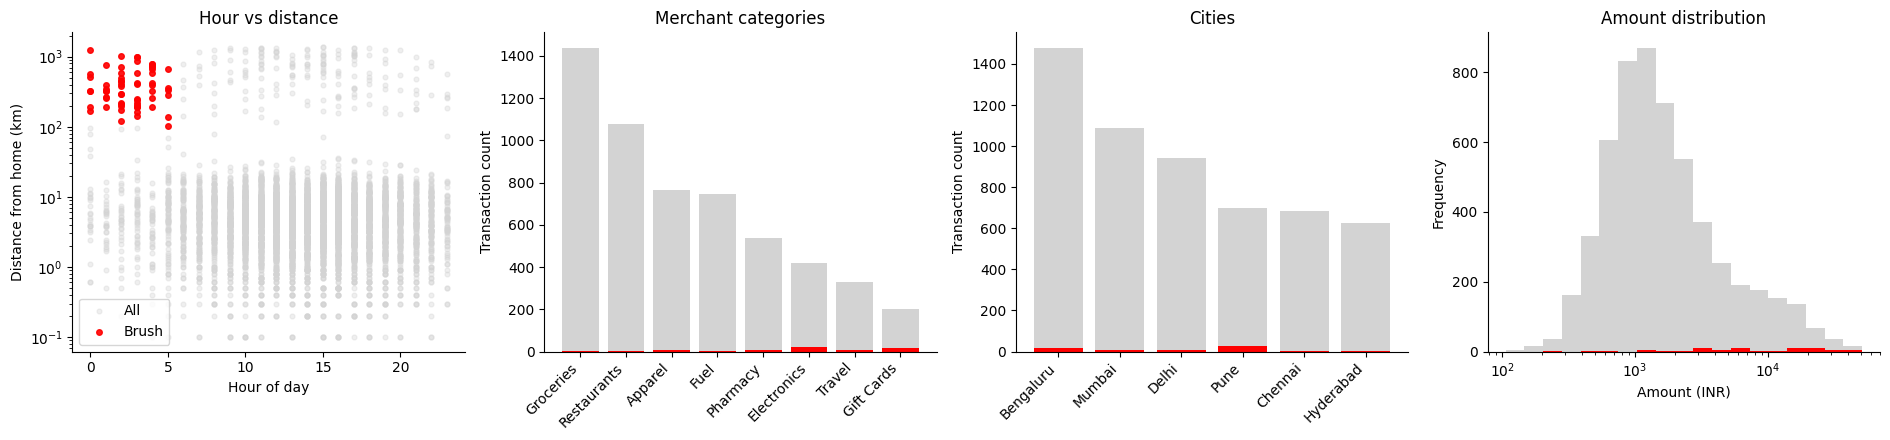

Number of transactions brushed: 61
Fraud rate in brush: 86.89%; overall: 2.17%
Share of all confirmed fraud captured: 44.17%


In [3]:
# Coordinated views use ONE consistent brush across all four panels.
brush = tx['night'].eq(True) & tx['distance_from_home_km'].gt(100)
fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))

# (a) Hour versus distance. Plot only positive distances for a valid logarithmic axis.
valid_distance = tx.distance_from_home_km > 0
axes[0].scatter(tx.loc[valid_distance, 'hour'], tx.loc[valid_distance, 'distance_from_home_km'],
                color='lightgray', alpha=0.35, s=12, label='All')
axes[0].scatter(tx.loc[brush & valid_distance, 'hour'], tx.loc[brush & valid_distance, 'distance_from_home_km'],
                color='red', alpha=0.9, s=16, label='Brush')
axes[0].set(xlabel='Hour of day', ylabel='Distance from home (km)', title='Hour vs distance')
axes[0].set_yscale('log')
axes[0].legend()

# (b) Categories with numeric bar positions (avoids set_ticklabels warnings).
for ax, field, title in [(axes[1], 'merchant_category', 'Merchant categories'),
                         (axes[2], 'city', 'Cities')]:
    totals = tx[field].value_counts()
    selected = tx.loc[brush, field].value_counts().reindex(totals.index, fill_value=0)
    positions = np.arange(len(totals))
    ax.bar(positions, totals.values, color='lightgray', label='All')
    ax.bar(positions, selected.values, color='red', label='Brush')
    ax.set_xticks(positions, totals.index, rotation=45, ha='right')
    ax.set(title=title, ylabel='Transaction count')

# (d) Log-scaled transaction-amount distribution.
positive_amounts = tx.amount_inr > 0
bins = np.geomspace(tx.loc[positive_amounts, 'amount_inr'].min(),
                    tx.loc[positive_amounts, 'amount_inr'].max(), 20)
axes[3].hist(tx.loc[positive_amounts, 'amount_inr'], bins=bins, color='lightgray', label='All')
axes[3].hist(tx.loc[brush & positive_amounts, 'amount_inr'], bins=bins, color='red', label='Brush')
axes[3].set_xscale('log')
axes[3].set(xlabel='Amount (INR)', ylabel='Frequency', title='Amount distribution')

plt.tight_layout()
plt.show()
num_brushed = int(brush.sum())
overall_rate = tx.is_fraud.mean()
brush_rate = tx.loc[brush, 'is_fraud'].mean() if num_brushed else float('nan')
share_fraud = tx.loc[brush, 'is_fraud'].sum() / tx.is_fraud.sum() if tx.is_fraud.sum() else float('nan')
print(f'Number of transactions brushed: {num_brushed}')
print(f'Fraud rate in brush: {brush_rate:.2%}; overall: {overall_rate:.2%}')
print(f'Share of all confirmed fraud captured: {share_fraud:.2%}')


The night-time, far-from-home rule captures 44.17% of all fraud cases. This indicates that while the rule is highly precise (86.89% fraud rate), relying on it exclusively leaves more than half of the company's fraud undetected. The City Counts linked view showed high overall transaction counts elsewhere, indicating that other patterns—like the Pune cluster—were taking place in normal hours near home.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
import time
import numpy as np
import pandas as pd

# Ensure dataset is loaded if setup cell was not run yet
try:
    tx
except NameError:
    tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
    tx["night"] = tx.hour < 6
    tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

big = pd.concat([tx] * 182, ignore_index=True)

# --- TODO 1 ---
times = []
for _ in range(5):
    start = time.perf_counter()
    res = big[(big['detector_score'] >= 0.6) & (big['amount_inr'] > 3000)]
    end = time.perf_counter()
    times.append(end - start)
best_s = min(times)

# --- TODO 2 ---
per_item_us = (best_s / len(big)) * 1e6
max_rows = (0.1 / (per_item_us / 1e6))

# --- TODO 3 ---
t_50m = (50000000 * (per_item_us / 1e6))
skip_pct = max(0.0, (1 - (max_rows / 50000000)) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 9.4 ms -> 0.0094 us/row -> max 10,660,190 rows in 0.1 s
50M rows -> 0.47 s; must skip 78.7% of rows to stay under 0.1 s


An alternative reduce technique is aggregation (e.g., binning transactions into hour/day averages or spatial clusters). While this lets the query run instantly on 50M rows, the analyst loses drill-down / granularity capabilities, meaning they can no longer view or select individual outlier transactions to inspect their distinct properties.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

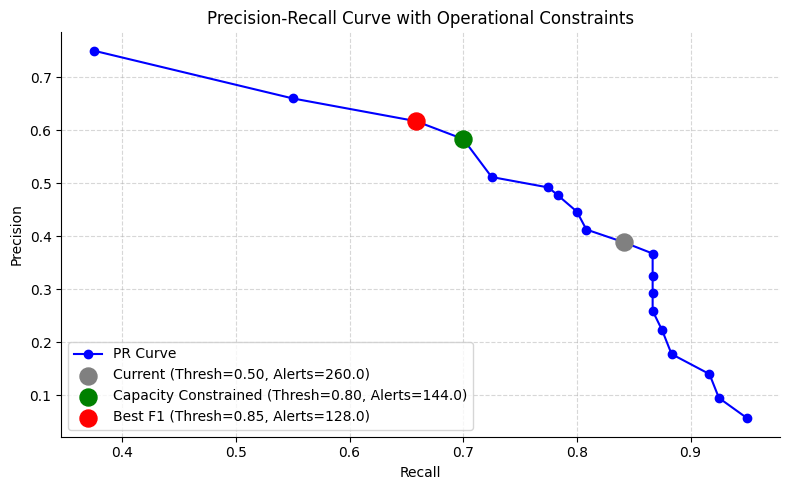

Recommendation: Shift threshold to 0.80 (Alerts: 144.0, Recall: 70.00%, Precision: 58.33%) to meet operational budget while capturing maximal fraud.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure dataset is loaded if setup cell was not run yet
try:
    tx
except NameError:
    tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
    tx["night"] = tx.hour < 6
    tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

rows = []
# --- TODO 1 ---
thresholds = np.arange(0.05, 1.0, 0.05)
for thresh in thresholds:
    flagged = tx['detector_score'] >= thresh
    tp = ((flagged == True) & (tx['is_fraud'] == 1)).sum()
    fp = ((flagged == True) & (tx['is_fraud'] == 0)).sum()
    fn = ((flagged == False) & (tx['is_fraud'] == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    rows.append({
        'threshold': thresh,
        'alerts': flagged.sum(),
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'precision': precision,
        'recall': recall,
        'F1': f1
    })
pr = pd.DataFrame(rows)

# --- TODO 2 ---
# Under 150 alerts max-recall threshold
under_capacity = pr[pr['alerts'] <= 150]
capacity_choice = under_capacity.loc[under_capacity['recall'].idxmax()]
best_f1 = pr.loc[pr['F1'].idxmax()]
current_choice = pr.loc[np.abs(pr['threshold'] - 0.5).idxmin()]

# --- TODO 3 ---
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr['recall'], pr['precision'], marker='o', color='b', label='PR Curve')
ax.scatter(current_choice['recall'], current_choice['precision'], color='grey', s=150, zorder=5, label=f"Current (Thresh=0.50, Alerts={current_choice['alerts']})")
ax.scatter(capacity_choice['recall'], capacity_choice['precision'], color='green', s=150, zorder=5, label=f"Capacity Constrained (Thresh={capacity_choice['threshold']:.2f}, Alerts={capacity_choice['alerts']})")
ax.scatter(best_f1['recall'], best_f1['precision'], color='red', s=150, zorder=5, label=f"Best F1 (Thresh={best_f1['threshold']:.2f}, Alerts={best_f1['alerts']})")

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve with Operational Constraints')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# --- TODO 4 ---
print(f"Recommendation: Shift threshold to {capacity_choice['threshold']:.2f} (Alerts: {capacity_choice['alerts']}, Recall: {capacity_choice['recall']:.2%}, Precision: {capacity_choice['precision']:.2%}) to meet operational budget while capturing maximal fraud.")

The decision belongs entirely to the Head of Fraud Ops, as the model cannot gauge the real-world costs of missing fraud versus overloading a team. Keeping a human in the loop allows us to merge raw metrics with actual operational budgets (the 150-review limit), allowing human managers to evaluate trade-offs and drive model parameters dynamically.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# Requested interaction: independently zoomable, selectable Plotly scatter and
# city -> merchant-category sunburst with hover-for-details.
flagged = tx.loc[tx.detector_score >= 0.3].copy()
fig1 = px.scatter(
    flagged, x='timestamp', y='amount_inr', color='label',
    hover_data=['txn_id', 'customer_id', 'city', 'merchant_category',
                'distance_from_home_km', 'detector_score'],
    log_y=True, title='Flagged transactions (score >= 0.3)',
    color_discrete_map={'confirmed fraud': 'red', 'legitimate': 'grey'},
)
fig1.update_layout(dragmode='select')
fig1.show()

sun_data = (tx.groupby(['city', 'merchant_category'])
            .agg(count=('is_fraud', 'size'), fraud_rate=('is_fraud', 'mean'))
            .reset_index())
fig2 = px.sunburst(
    sun_data, path=['city', 'merchant_category'], values='count', color='fraud_rate',
    color_continuous_scale='Reds',
    title='Drill down from city to merchant category (size=count, colour=fraud rate)',
)
fig2.show()

# Both plots are interactive, but selection is NOT automatically cross-linked.
# True event-linked brushing requires a FigureWidget/Dash callback; it was not
# requested by this task, unlike the common-mask demonstration in Task 2.


Hovering on 400 separate cases is highly tedious and induces immense cognitive load. It prevents our team from spotting macro relationships across records. The reordered matrix heatmap from Task 1 fixes this by rendering all patterns, clusters, and temporal trends instantly visible in a single global view.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

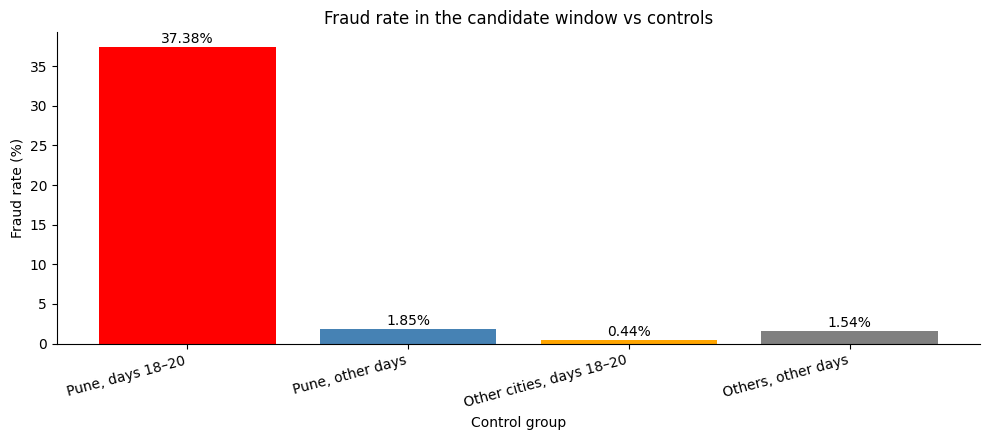

Pune days 18–20: 37.38% fraud; outside window: 1.48% fraud
Pune on other days: 1.85%; other cities on days 18–20: 0.44%
Chi-square p-value: 1.06e-136 (test of association, not proof of coordination)
Verdict: statistically unusual localized fraud concentration; investigate possible coordination.
Caution: the window was selected after visually inspecting these data, so the p-value is exploratory.


In [7]:
from scipy.stats import chi2_contingency

# H0: fraud and the Pune/Days 18-20 indicator are independent.
# H1: there is an association between fraud and that indicator.
in_window = tx.city.eq('Pune') & tx.day.isin([18, 19, 20])
contingency = pd.crosstab(in_window, tx.is_fraud).reindex(index=[False, True], columns=[0, 1], fill_value=0)
chi2, p_val, dof, expected = chi2_contingency(contingency)

def fraud_rate(mask):
    series = tx.loc[mask, 'is_fraud']
    return series.mean() if not series.empty else float('nan')

same_city = tx.city.eq('Pune')
same_days = tx.day.isin([18, 19, 20])
rate_in = fraud_rate(in_window)
rate_out = fraud_rate(~in_window)
rate_same_city_other_days = fraud_rate(same_city & ~same_days)
rate_other_cities_same_days = fraud_rate(~same_city & same_days)
rate_rest = fraud_rate(~same_city & ~same_days)

labels_bar = ['Pune, days 18–20', 'Pune, other days', 'Other cities, days 18–20', 'Others, other days']
rates = [rate_in, rate_same_city_other_days, rate_other_cities_same_days, rate_rest]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(4), [r * 100 for r in rates], color=['red', 'steelblue', 'orange', 'grey'])
ax.set_xticks(range(4), labels_bar, rotation=15, ha='right')
ax.set(xlabel='Control group', ylabel='Fraud rate (%)', title='Fraud rate in the candidate window vs controls')
for i, rate in enumerate(rates):
    if np.isfinite(rate):
        ax.text(i, rate * 100 + 0.5, f'{rate:.2%}', ha='center')
plt.tight_layout()
plt.show()

print(f'Pune days 18–20: {rate_in:.2%} fraud; outside window: {rate_out:.2%} fraud')
print(f'Pune on other days: {rate_same_city_other_days:.2%}; other cities on days 18–20: {rate_other_cities_same_days:.2%}')
print(f'Chi-square p-value: {p_val:.3g} (test of association, not proof of coordination)')
if p_val < 0.05 and rate_in > rate_out:
    print('Verdict: statistically unusual localized fraud concentration; investigate possible coordination.')
else:
    print('Verdict: insufficient evidence of an elevated localized fraud concentration.')
print('Caution: the window was selected after visually inspecting these data, so the p-value is exploratory.')


The opposite result — similar spikes across other cities on days 18–20 — would weaken the claim that the pattern is specifically localized to Pune and suggest a broader event. The observed concentration alone still does not establish common perpetrators or coordination. We would need additional independent evidence (for example, linked accounts, devices or merchant behaviour) and ideally a holdout period to test the hypothesis after selecting the window.

**Final Fraud-Ops Recommendation:**

The supplied dataset contains **120 confirmed fraud transactions out of 5,520**. The dashboard identifies an unusually concentrated cluster in **Pune on days 18–20**. The chi-square comparison provides strong evidence of an association between confirmed fraud and this city/day window, but does **not** by itself prove a coordinated fraud ring; the window was selected after inspecting the same data, so this is an exploratory result requiring independent investigation.

At a **0.80 detector-score threshold**, the saved analysis produced **144 alerts**, within the team's **150-review capacity**, with **70% recall** and **58.33% precision**. This is a capacity-constrained operational choice rather than perfect fraud detection. Prioritize the reordered city/day matrix for overview, use the Plotly scatter and sunburst for case inspection, and incorporate confirmed investigator feedback into subsequent model validation. Recheck the threshold as volume and fraud patterns change.